In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score


In [2]:
POLLUTANT = "pm25"
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
MAX_CLUSTERS = 8

PROCESSED_DIR = Path("../data/processed")
FEATURES_FILE = PROCESSED_DIR / f"features_{POLLUTANT}.parquet"

In [3]:
df = pd.read_parquet(FEATURES_FILE)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [4]:
lag_cols = [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS]
rolling_cols = [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS]
rolling_std_cols = [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS]
calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
weather_cols = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "wind_speed_10m_mean",
    "precipitation_sum",
    "pressure_msl_mean",
]


In [5]:
base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
required = base_cols + ["date", "station_id", POLLUTANT]
cluster_df = df.dropna(subset=required).copy().reset_index(drop=True)

In [6]:
wind_dummies = pd.get_dummies(cluster_df["wind_category"], prefix="wind")
X_cont = RobustScaler().fit_transform(cluster_df[base_cols])
X = pd.concat([
    pd.DataFrame(X_cont, columns=base_cols),
    wind_dummies.reset_index(drop=True),
], axis=1)

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X)
print(f"Clustering rows: {len(cluster_df):,} | input features: {X.shape[1]} | PCA components: {X_pca.shape[1]} "
      f"({pca.explained_variance_ratio_.sum():.1%} variance kept)")


Clustering rows: 1,912 | input features: 21 | PCA components: 2 (90.1% variance kept)


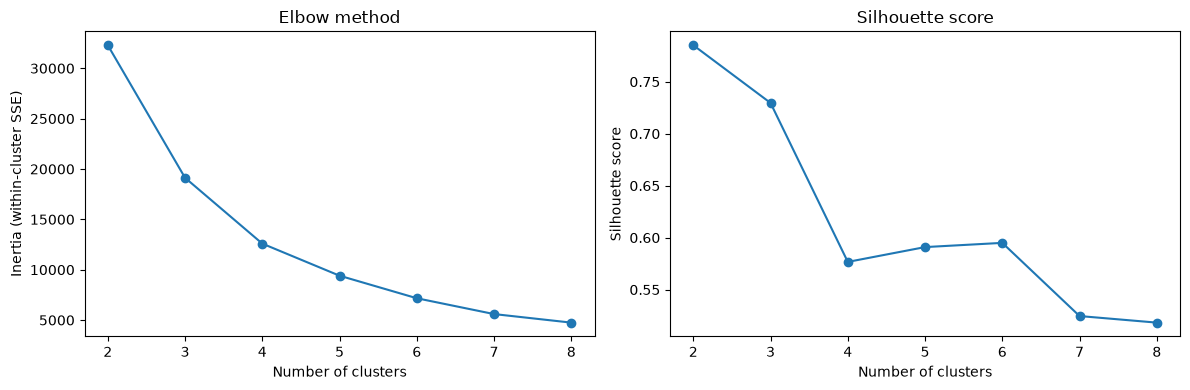

In [7]:
inertias = []
silhouettes = []
ks = range(2, MAX_CLUSTERS + 1)

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow method")

axes[1].plot(list(ks), silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")

plt.tight_layout()
plt.show()


In [8]:
best_k = int(ks[np.argmax(silhouettes)])
print(f"Best number of clusters by silhouette: {best_k}")

Best number of clusters by silhouette: 2


In [9]:
N_CLUSTERS = best_k

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

gmm = GaussianMixture(n_components=N_CLUSTERS, random_state=42)
gmm_labels = gmm.fit_predict(X_pca)

sil_kmeans = silhouette_score(X_pca, kmeans_labels)
sil_gmm = silhouette_score(X_pca, gmm_labels)
print(f"Silhouette K-Means: {sil_kmeans:.3f}")
print(f"Silhouette GMM    : {sil_gmm:.3f}")

cluster_df["cluster_kmeans"] = kmeans_labels
cluster_df["cluster_gmm"] = gmm_labels


Silhouette K-Means: 0.785
Silhouette GMM    : 0.361


In [10]:
def describe_clusters(frame, label_col):
    frame = frame.copy()
    frame["month"] = frame["date"].dt.month
    frame["season"] = frame["month"].map({
        12: "winter", 1: "winter", 2: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "autumn", 10: "autumn", 11: "autumn",
    })
    summary = (
        frame.groupby(label_col)
        .agg(count=("station_id", "size"),
             pm_mean=("pm25" if POLLUTANT == "pm25" else "pm10", "mean"),
             mean_month=("month", "mean"),
             top_season=("season", lambda s: s.mode().iloc[0]),
             n_stations=("station_id", "nunique"))
        .reset_index()
    )
    summary["mean_month"] = summary["mean_month"].round(1)
    return summary


In [11]:
for label_col in ["cluster_kmeans", "cluster_gmm"]:
    print(label_col)
    display(describe_clusters(cluster_df, label_col))

cluster_kmeans


,cluster_kmeans,count,pm_mean,mean_month,top_season,n_stations
0,0,1743,25.497889,7.0,summer,5
1,1,169,16.466565,7.5,autumn,5


cluster_gmm


,cluster_gmm,count,pm_mean,mean_month,top_season,n_stations
0,0,1244,26.963748,7.0,summer,5
1,1,668,20.483187,7.2,autumn,5


In [12]:
LABELS_OUT = PROCESSED_DIR / f"clustering_labels_{POLLUTANT}.parquet"
SUMMARY_COLS = ["station_id", "station_name", "date", POLLUTANT, "cluster_kmeans", "cluster_gmm"]

In [13]:
cluster_df[SUMMARY_COLS].to_parquet(LABELS_OUT, index=False)

summary_list = []
for label_col in ["cluster_kmeans", "cluster_gmm"]:
    s = describe_clusters(cluster_df, label_col)
    s["method"] = label_col
    summary_list.append(s)
summary_df = pd.concat(summary_list, ignore_index=True)
summary_df.to_parquet(PROCESSED_DIR / f"clustering_summary_{POLLUTANT}.parquet", index=False)

print(f"Saved: clustering_labels_{POLLUTANT}.parquet")
print(f"Saved: clustering_summary_{POLLUTANT}.parquet")


Saved: clustering_labels_pm25.parquet
Saved: clustering_summary_pm25.parquet
